In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, MaxAbsScaler

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    multilabel_confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')


In [2]:
df = pd.read_csv("insurance_claims_10k.csv")
df.head()

,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,...,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,fraud_reported,_c39
0,278,47,581816,"Feb 25, 1990",oh,250/500,1000,1242.21,3000000,463-337,...,NO,68210,NaN,6200,55810,Toyota,Camry,1995,Y,NaN
1,464,57,978555,30-07-1992,IN,100/300,1000,1583.55,0,433924,...,NO,66180,6020,12030,48130,Saab,93,2014,N,NaN
2,170,32,618236,20030401,OH,500/1000,2000,1221.12,0,441485,...,?,61990,6200,6200,49590,Dodge,RAM,1997,N,NaN
3,157,37,702580,09-09-1992,INDIANA,500/1000,NaN,912.65,0,620800,...,YES,69550,"$6,960",13910,48680,saab,95,2005,N,NaN
4,238,36,851599,05-04-2013,IN,500/1000,2000,1506.72,6000000,463938,...,YES,46360,9270,4640,32450,Dodge,RAM,2005,Y,NaN


In [3]:
df.shape

(10000, 40)

In [4]:
df.columns

Index(['months_as_customer', 'age', 'policy_number', 'policy_bind_date',
       'policy_state', 'policy_csl', 'policy_deductable',
       'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'insured_sex',
       'insured_education_level', 'insured_occupation', 'insured_hobbies',
       'insured_relationship', 'capital-gains', 'capital-loss',
       'incident_date', 'incident_type', 'collision_type', 'incident_severity',
       'authorities_contacted', 'incident_state', 'incident_city',
       'incident_location', 'incident_hour_of_the_day',
       'number_of_vehicles_involved', 'property_damage', 'bodily_injuries',
       'witnesses', 'police_report_available', 'total_claim_amount',
       'injury_claim', 'property_claim', 'vehicle_claim', 'auto_make',
       'auto_model', 'auto_year', 'fraud_reported', '_c39'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   months_as_customer           9871 non-null   str    
 1   age                          9773 non-null   str    
 2   policy_number                9987 non-null   str    
 3   policy_bind_date             9853 non-null   str    
 4   policy_state                 9947 non-null   str    
 5   policy_csl                   9941 non-null   str    
 6   policy_deductable            9937 non-null   str    
 7   policy_annual_premium        9756 non-null   str    
 8   umbrella_limit               9711 non-null   str    
 9   insured_zip                  9876 non-null   str    
 10  insured_sex                  9937 non-null   str    
 11  insured_education_level      9818 non-null   str    
 12  insured_occupation           9775 non-null   str    
 13  insured_hobbies             

In [6]:
df.describe()

,_c39
count,0.0
mean,NaN
std,NaN
min,NaN
25%,NaN
50%,NaN
75%,NaN
max,NaN


In [7]:
df.isnull().sum()

months_as_customer               129
age                              227
policy_number                     13
policy_bind_date                 147
policy_state                      53
policy_csl                        59
policy_deductable                 63
policy_annual_premium            244
umbrella_limit                   289
insured_zip                      124
insured_sex                       63
insured_education_level          182
insured_occupation               225
insured_hobbies                  132
insured_relationship             121
capital-gains                    366
capital-loss                     406
incident_date                     31
incident_type                     46
collision_type                   184
incident_severity                106
authorities_contacted           1135
incident_state                    50
incident_city                    124
incident_location                191
incident_hour_of_the_day         161
number_of_vehicles_involved       99
p

In [8]:
df = df.drop(["_c39","incident_location","policy_number","insured_zip", "insured_occupation", "insured_hobbies", "incident_city", "auto_model"],axis=1)
df = df.dropna(subset="fraud_reported")
df = df.drop_duplicates()

In [9]:
df['fraud_reported'] = df['fraud_reported'].replace({
    'Y': 'Yes',
    'y': 'Yes',
    'Yes': 'Yes',
    'yes': 'Yes',
    'TRUE': 'Yes',
    'true': 'Yes',
    '1': 'Yes',
    'Fraud': 'Yes',

    'N': 'No',
    'n': 'No',
    'No': 'No',
    'no': 'No',
    'FALSE': 'No',
    'false': 'No',
    '0': 'No',
    'Non-Fraud': 'No'
})
df['fraud_reported'].unique()
df['fraud_reported'] = df['fraud_reported'].map({'Yes': 1, 'No': 0})

In [10]:
df.isnull().sum()

months_as_customer              126
age                             225
policy_bind_date                145
policy_state                     50
policy_csl                       58
policy_deductable                61
policy_annual_premium           236
umbrella_limit                  280
insured_sex                      61
insured_education_level         176
insured_relationship            115
capital-gains                   356
capital-loss                    393
incident_date                    30
incident_type                    45
collision_type                  177
incident_severity               101
authorities_contacted          1107
incident_state                   47
incident_hour_of_the_day        154
number_of_vehicles_involved      98
property_damage                 241
bodily_injuries                 178
witnesses                       215
police_report_available         221
total_claim_amount               98
injury_claim                    238
property_claim              

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 9710 entries, 0 to 9999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   months_as_customer           9584 non-null   str  
 1   age                          9485 non-null   str  
 2   policy_bind_date             9565 non-null   str  
 3   policy_state                 9660 non-null   str  
 4   policy_csl                   9652 non-null   str  
 5   policy_deductable            9649 non-null   str  
 6   policy_annual_premium        9474 non-null   str  
 7   umbrella_limit               9430 non-null   str  
 8   insured_sex                  9649 non-null   str  
 9   insured_education_level      9534 non-null   str  
 10  insured_relationship         9595 non-null   str  
 11  capital-gains                9354 non-null   str  
 12  capital-loss                 9317 non-null   str  
 13  incident_date                9680 non-null   str  
 14  incident

## Prafull

### Column - months_as_customer

In [12]:
# Check data type and non-null count
df["months_as_customer"].info()

# Summary statistics (including min, max, percentiles)
print(df["months_as_customer"].describe())

#Cleaning special symbols like '$' and ','
df["months_as_customer"] = (
    df["months_as_customer"]
    .astype(str)
    .str.replace(r'[\$,#,-]', '', regex=True)
    .str.strip()
)

#Replacing known missing string indicators with actual NaN
missing_placeholders = ['?', 'unknown', '-', '', 'nan', 'NaN', 'None']
df["months_as_customer"] = df["months_as_customer"].replace(missing_placeholders, np.nan)

df["months_as_customer"] = pd.to_numeric(df["months_as_customer"], errors='coerce')

# Handle out-of-bound unrealistic values (e.g., negative or > 600 months)
df.loc[
    (df["months_as_customer"] < 0) | (df["months_as_customer"] > 600),
    "months_as_customer",
] = np.nan

# Impute using median
df["months_as_customer"] = df["months_as_customer"].fillna(df["months_as_customer"].median())

# Convert to integer type
df["months_as_customer"] = df["months_as_customer"].astype(int)

# # Feature Engineering: Binning into tenure cohorts
# df["tenure_group"] = pd.cut(
#     df["months_as_customer"],
#     bins=[-1, 12, 60, 120, 240, 360, 600],
#     labels=["0-12", "13-60", "61-120", "121-240", "241-360", "361-600"],
# )

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: months_as_customer
Non-Null Count  Dtype
--------------  -----
9584 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
count     9584
unique     653
top          0
freq       178
Name: months_as_customer, dtype: object


In [13]:
df["months_as_customer"].dtype

dtype('int64')

<Axes: xlabel='months_as_customer', ylabel='Density'>

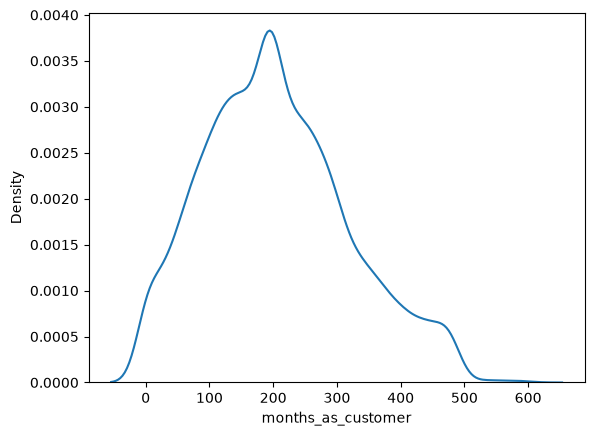

In [14]:
sns.kdeplot(df["months_as_customer"])

In [15]:
# IQR Outlier Analysis

Q1 = df["months_as_customer"].quantile(0.25)
Q3 = df["months_as_customer"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["months_as_customer"] < lower_bound)
    | (df["months_as_customer"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 20


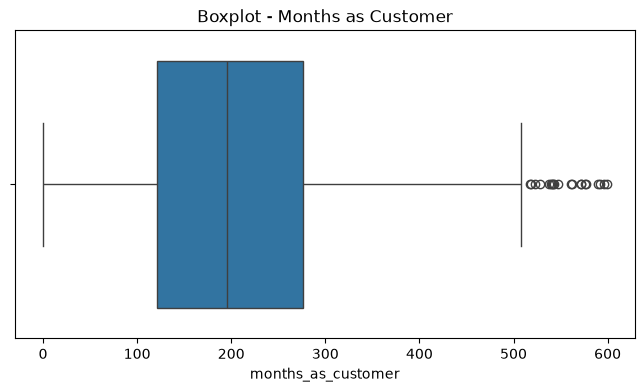

In [16]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["months_as_customer"])
plt.title("Boxplot - Months as Customer")
plt.show()

### Outliers capping

In [17]:
# Outliers capping

df["months_as_customer"] = df["months_as_customer"].clip(
    lower=lower_bound, upper=upper_bound
)

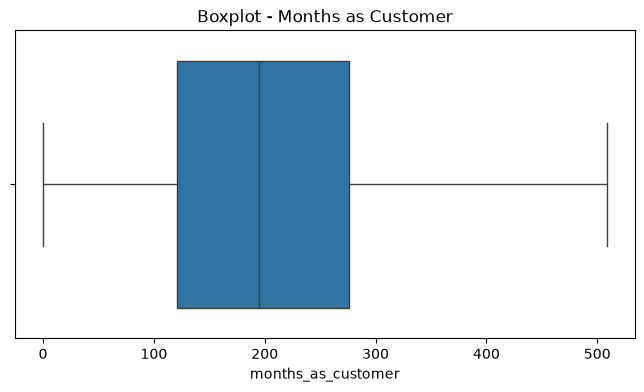

In [18]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["months_as_customer"])
plt.title("Boxplot - Months as Customer")
plt.show()

### Column - age

In [19]:
# Check data type and non-null count
df["age"].info()

# Summary statistics (including min, max, percentiles)
print(df["age"].describe())

#Cleaning special symbols like '$' and ','
df["age"] = (
    df["age"]
    .astype(str)
    .str.replace(r'[\$,#,-]', '', regex=True)
    .str.strip()
)

#Replacing known missing string indicators with actual NaN
missing_placeholders = ['?', 'unknown', '-', '', 'nan', 'NaN', 'None']
df["age"] = df["age"].replace(missing_placeholders, np.nan)

df["age"] = pd.to_numeric(df["age"], errors='coerce')

# Handle out-of-bound unrealistic values (e.g., negative or > 600 months)
df.loc[
    (df["age"] < 0) | (df["age"] > 600),
    "age",
] = np.nan

# Impute using median
df["age"] = df["age"].fillna(df["age"].median())

# Convert to integer type
df["age"] = df["age"].astype(int)

# # Feature Engineering: Binning age into cohorts
# df["age_group"] = pd.cut(
#     df["age"],
#     bins=[17, 25, 35, 50, 65, 100],
#     labels=["18-25", "26-35", "36-50", "51-65", "66+"],
# )

# # Verify the value counts of your new age groups
# print(df["age_group"].value_counts())

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: age
Non-Null Count  Dtype
--------------  -----
9485 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
count     9485
unique     113
top         39
freq       409
Name: age, dtype: object


In [20]:
df["age"].dtype

dtype('int64')

<Axes: xlabel='age', ylabel='Density'>

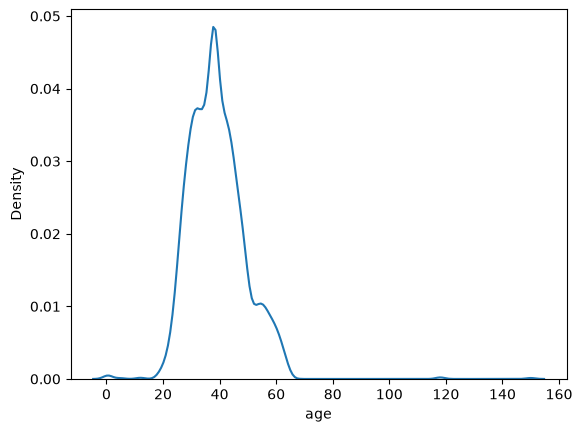

In [21]:
sns.kdeplot(df["age"])

In [22]:
# IQR Outlier Analysis

Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["age"] < lower_bound)
    | (df["age"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 69


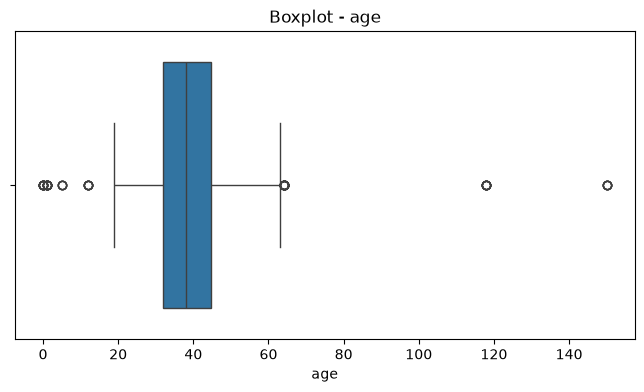

In [23]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["age"])
plt.title("Boxplot - age")
plt.show()

In [24]:
# Outliers capping

df["age"] = df["age"].clip(
    lower=lower_bound, upper=upper_bound
)

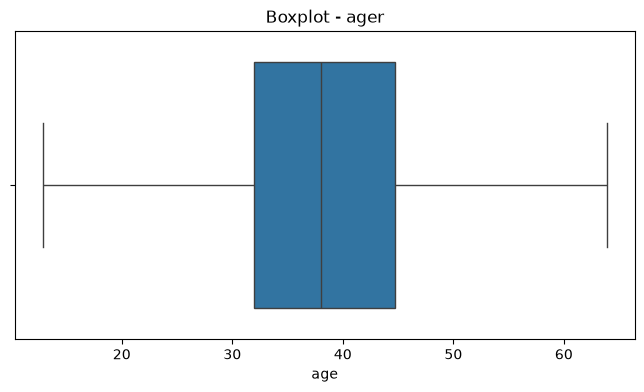

In [25]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["age"])
plt.title("Boxplot - ager")
plt.show()

## Column - policy_bind_date

In [26]:
df['policy_bind_date'].info()

df['policy_bind_date'].describe()

# Convert to datetime handling mixed formats automatically
df['policy_bind_date'] = pd.to_datetime(
    df['policy_bind_date'], format='mixed', dayfirst=True, errors='coerce'
)

# Check count of missing/invalid dates
missing_dates = df['policy_bind_date'].isna().sum()
print(f"Total missing dates: {missing_dates}")

# Option 1: Fill missing dates with the median date of the column
median_date = df['policy_bind_date'].median()
df['policy_bind_date'] = df['policy_bind_date'].fillna(median_date)

# Option 2 (Alternative): Fill with a specific fixed default date string
# df['policy_bind_date'] = df['policy_bind_date'].fillna(pd.to_datetime('1990-01-01'))

# Verify that there are zero missing dates left
print(f"Remaining missing dates after fill: {df['policy_bind_date'].isna().sum()}")


<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: policy_bind_date
Non-Null Count  Dtype
--------------  -----
9565 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Total missing dates: 187
Remaining missing dates after fill: 0


In [27]:
# IQR Outlier Analysis

Q1 = df["policy_bind_date"].quantile(0.25)
Q3 = df["policy_bind_date"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["policy_bind_date"] < lower_bound)
    | (df["policy_bind_date"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 10


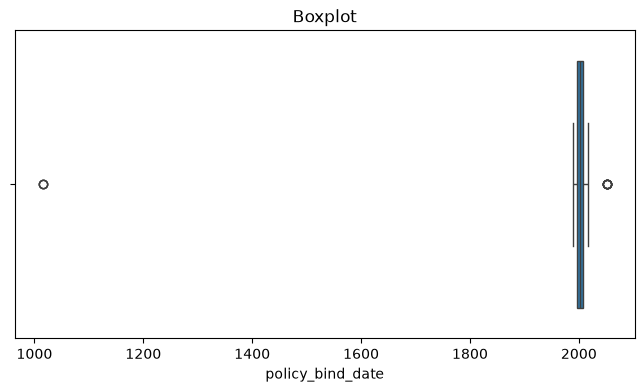

In [28]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["policy_bind_date"])
plt.title("Boxplot")
plt.show()

In [29]:
# Outliers capping

df["policy_bind_date"] = df["policy_bind_date"].clip(
    lower=lower_bound, upper=upper_bound
)

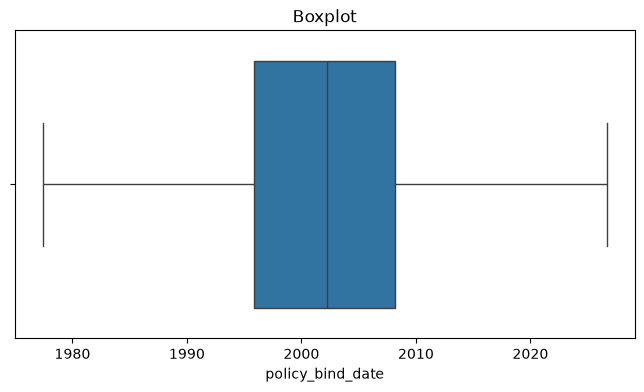

In [30]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["policy_bind_date"])
plt.title("Boxplot")
plt.show()

In [31]:
df['policy_bind_date'].describe()

count                          9710
mean     2002-03-16 04:16:13.594232
min             1977-06-07 09:00:00
25%             1995-11-23 06:00:00
50%             2002-04-08 00:00:00
75%             2008-03-14 12:00:00
max             2026-08-30 09:00:00
Name: policy_bind_date, dtype: object

In [32]:
"""
Machine learning models cannot directly take datetime objects. 
Once converted to datetime, extract useful numeric feature components:
"""
# Extract datetime features (using the clean column name without extra spaces)
df['policy_bind_year'] = df['policy_bind_date'].dt.year.astype("Int64")
df['policy_bind_month'] = df['policy_bind_date'].dt.month.astype("Int64")
df['policy_bind_day'] = df['policy_bind_date'].dt.day.astype("Int64")

# Drop the original datetime column to prevent type errors in model training & VIF calculations
df = df.drop(columns=['policy_bind_date'])

## Column - policy_state

In [33]:
df['policy_state'].info()

df['policy_state'].describe()

df['policy_state'].unique()


import difflib

# 1. Define the exact target categories
valid_categories = [
    'ILLINOIS',
    'INDIANA',
    'OHIO'
]

# 2. Step 1: Pre-clean whitespace and normalize formatting
# Convert to string, lowercase, strip spaces, and normalize underscores/extra spaces
df['policy_state_clean'] = (
    df['policy_state']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Replace common unknown/null placeholders with NaN upfront
invalid_placeholders = ['nan', 'None', 'null', '?', '-', 'Unknown', ' ', '']
df['policy_state_clean'] = df['policy_state_clean'].replace(invalid_placeholders, np.nan)

# 3. Step 2: Build auto_typo_map using difflib
auto_typo_map = {}

# Convert valid categories to lowercase for matching
valid_categories_lower = [cat.lower() for cat in valid_categories]

for val in df['policy_state_clean'].dropna().unique():
    val_lower = val.lower()
    
    # Check close matches using string similarity
    matches = difflib.get_close_matches(val_lower, valid_categories_lower, n=1, cutoff=0.4)
    
    if matches:
        # Find index of matched lower string to get the correctly capitalized category
        matched_idx = valid_categories_lower.index(matches[0])
        auto_typo_map[val] = valid_categories[matched_idx]

# 4. Step 3: Map mapped values back onto the clean column
df['policy_state'] = df['policy_state_clean'].map(auto_typo_map)

# Remove temporary clean working column
df.drop(columns=['policy_state_clean'], inplace=True)

# 5. Step 4: Verify the output
print("Unique categories remaining:", df['policy_state'].nunique())
print(df['policy_state'].value_counts(dropna=False))

# Replaced NaN values with 'Unknown'
df['policy_state'] = df['policy_state'].fillna('Unknown')

df['policy_state'].unique()

# Applied one-hot encoding
df = pd.get_dummies(df, columns=['policy_state'], drop_first=False, dtype=int)

# droping "policy_state_Unknown" column
df.drop(columns=['policy_state_Unknown'], inplace=True)

# Verified one-hot encoded Feature by filtering all dummy columns created for policy_state
encoded_cols_policy_state = [col for col in df.columns if col.startswith('policy_state')]
print(encoded_cols_policy_state)

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: policy_state
Non-Null Count  Dtype
--------------  -----
9660 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Unique categories remaining: 3
policy_state
OHIO        3395
ILLINOIS    3324
INDIANA     2920
NaN           71
Name: count, dtype: int64
['policy_state_ILLINOIS', 'policy_state_INDIANA', 'policy_state_OHIO']


In [34]:
df[['policy_state_ILLINOIS', 'policy_state_INDIANA', 'policy_state_OHIO']].info()

<class 'pandas.DataFrame'>
Index: 9710 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   policy_state_ILLINOIS  9710 non-null   int64
 1   policy_state_INDIANA   9710 non-null   int64
 2   policy_state_OHIO      9710 non-null   int64
dtypes: int64(3)
memory usage: 303.4 KB


## column- policy_csl

In [35]:
# Step 1: Convert to uppercase and strip whitespace/special characters (fixed column name keys)
csl = df["policy_csl"].astype(str).str.upper()
csl = csl.str.replace(r"[\$,\s]", "", regex=True)
csl = csl.str.replace("-", "/", regex=False)
csl = csl.str.replace(r"(?<=\d)K", "", regex=True)
csl = csl.str.replace("1M", "1000", regex=False)

# Step 2: Define valid CSL categories and replace common placeholders with NaN
valid_csl = ["100/300", "250/500", "500/1000"]
missing_placeholders = ["?", "UNKNOWN", "-", "--", "NAN", "NONE", ""]
csl = csl.replace(missing_placeholders, np.nan)

# Step 3: Keep only valid limits, coerce others/typos to NaN
df["policy_csl"] = csl.where(csl.isin(valid_csl))

# Step 4: Fill missing values with the mode
mode_csl = df["policy_csl"].mode()[0]
df["policy_csl"] = df["policy_csl"].fillna(mode_csl)

# Step 5: Split into numeric component columns and cast as integer (int64)
df[["csl_per_person", "csl_per_accident"]] = (
    df["policy_csl"].str.split("/", expand=True).astype(int)
)

print("Unique policy_csl values after cleaning:")
print(df["policy_csl"].value_counts(dropna=False))

# Step 5: Apply One-Hot Encoding instead of .str.split()
df = pd.get_dummies(df, columns=["policy_csl"], drop_first=False, dtype=int)

print("Columns created after one-hot encoding policy_csl:")
print([col for col in df.columns if col.startswith('policy_csl')])

Unique policy_csl values after cleaning:
policy_csl
250/500     3544
100/300     3301
500/1000    2865
Name: count, dtype: int64
Columns created after one-hot encoding policy_csl:
['policy_csl_100/300', 'policy_csl_250/500', 'policy_csl_500/1000']


## column- policy_deductable

In [36]:
# Check data type and non-null count
df["policy_deductable"].info()

# Summary statistics (including min, max, percentiles)
print(df["policy_deductable"].describe())

# Cleaning special symbols like '$' and ','
df["policy_deductable"] = (
    df["policy_deductable"]
    .astype(str)
    .str.replace(r'[\$,#,-]', '', regex=True)
    .str.strip()
)

# Replacing known missing string indicators with actual NaN
missing_placeholders = ['?', 'unknown', '-', '', 'nan', 'NaN', 'None', '--']
df["policy_deductable"] = df["policy_deductable"].replace(missing_placeholders, np.nan)

# Convert to numeric, coercing any corrupt strings to NaN
df["policy_deductable"] = pd.to_numeric(df["policy_deductable"], errors='coerce')

# Handle out-of-bound or unrealistic values (e.g., negative or extreme values outside standard policy deductibles)
df.loc[
    (df["policy_deductable"] < 0) | (df["policy_deductable"] > 10000),
    "policy_deductable",
] = np.nan

# Impute using median
df["policy_deductable"] = df["policy_deductable"].fillna(df["policy_deductable"].median())

# Convert to integer type
df["policy_deductable"] = df["policy_deductable"].astype(int)

# Verify value counts after cleaning
print(df["policy_deductable"].value_counts(dropna=False))

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: policy_deductable
Non-Null Count  Dtype
--------------  -----
9649 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
count     9649
unique      11
top        500
freq      3289
Name: policy_deductable, dtype: object
policy_deductable
1000    3515
500     3347
2000    2848
Name: count, dtype: int64


In [37]:
# IQR Outlier Analysis

Q1 = df["policy_deductable"].quantile(0.25)
Q3 = df["policy_deductable"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["policy_deductable"] < lower_bound)
    | (df["policy_deductable"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 0


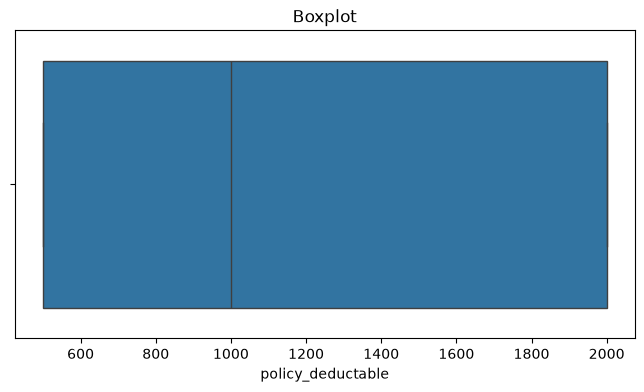

In [38]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["policy_deductable"])
plt.title("Boxplot")
plt.show()

## Kanchan

#### policy_annual_premium

In [39]:
df['policy_annual_premium'] = df['policy_annual_premium'].replace({
                                                    "null":np.nan,
                                                     "NULL":np.nan,
                                                     "N/A":np.nan,
                                                     "#NA":np.nan,
                                                     "?":np.nan,
                                                     "--":np.nan,
                                                     "":np.nan,
                                                     " ":np.nan
})

In [40]:
col = "policy_annual_premium"

# ---------- BEFORE: check ----------
print("Dtype before:", df[col].dtype)

# ---------- Step 1: Convert text to numbers (?, -, --, blank -> NaN) ----------
df[col] = (
    df[col]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("$", "", regex=False)
    .str.strip()
)
df[col] = pd.to_numeric(df[col], errors="coerce")   # keeps decimals like 1313.25

# ---------- Step 2: Fix negative values (sign error) ----------
df["premium_fixed_flag"] = (df[col] < 0).astype(int)
df[col] = df[col].abs()

# ---------- Step 3: Fix scale error (e.g. 124972 -> 1249.72) ----------
df.loc[df[col] > 10000, col] /= 100

# ---------- Step 4: 0 and 1 are not real premiums -> NaN ----------
print("Values <= 1:", (df[col] <= 1).sum())
df.loc[df[col] <= 1, col] = np.nan

# ---------- Step 5: Fill missing values with median ----------
print("Total missing before fill:", df[col].isna().sum())
median_val = df[col].median()
df[col] = df[col].fillna(median_val).round(2)

# ---------- Step 6: Outliers (IQR) ----------
Q1, Q3 = df[col].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
n_out = ((df[col] < lower) | (df[col] > upper)).sum()
print(f"Outliers: {n_out} ({n_out / len(df) * 100:.2f}%) | limits: {lower:.2f} to {upper:.2f}")

df["premium_capped"] = df[col].clip(lower=lower, upper=upper)

# ---------- Step 7: Explicit Numeric Type Conversion ----------
# Force conversion to float so pandas permanently registers it as float64
df[col] = pd.to_numeric(df[col], errors='coerce').astype(float)

# ---------- Step 8: Verify ----------
print("\n--- FINAL CHECK ---")
print("Dtype:", df[col].dtype)
print("Negatives left:", (df[col] < 0).sum())
print("Missing left:", df[col].isna().sum())
print("Min:", df[col].min(), "| Max:", df[col].max())
print(df[col].describe())

Dtype before: str
Values <= 1: 26
Total missing before fill: 412
Outliers: 129 (1.33%) | limits: 615.43 to 1886.48

--- FINAL CHECK ---
Dtype: float64
Negatives left: 0
Missing left: 0
Min: 62.31 | Max: 9325.0
count    9710.000000
mean     1253.538853
std       265.048523
min        62.310000
25%      1092.072500
50%      1258.920000
75%      1409.835000
max      9325.000000
Name: policy_annual_premium, dtype: float64


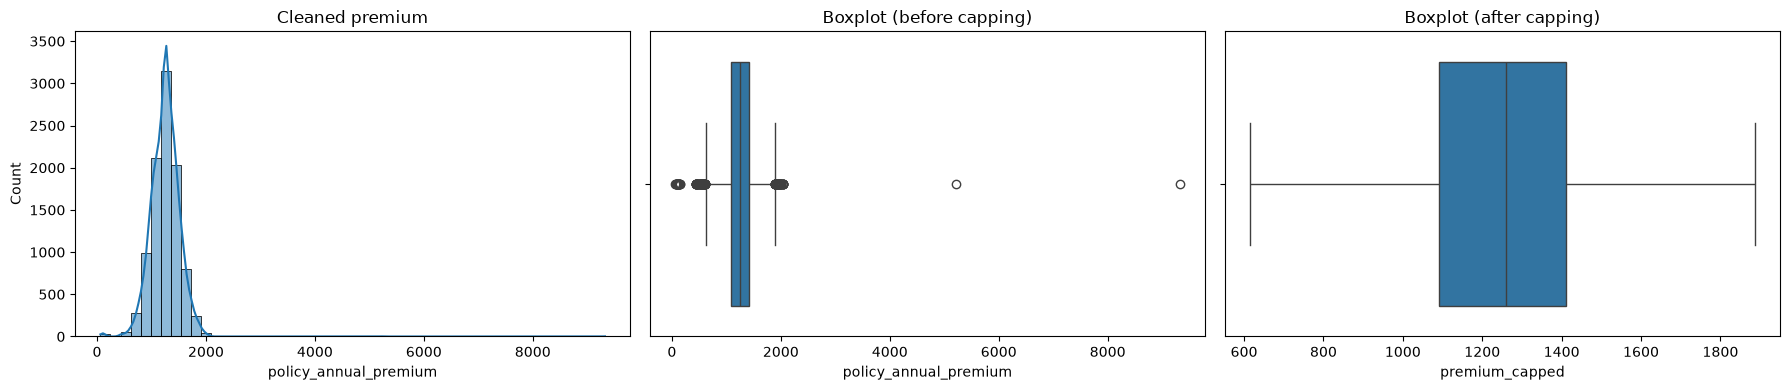

In [41]:
# ---------- Step 8: Plots before vs after capping ----------
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df[col], bins=50, kde=True, ax=ax[0]);  ax[0].set_title("Cleaned premium")
sns.boxplot(x=df[col], ax=ax[1]);                    ax[1].set_title("Boxplot (before capping)")
sns.boxplot(x=df["premium_capped"], ax=ax[2]);       ax[2].set_title("Boxplot (after capping)")
plt.tight_layout()
plt.show()

#### insured_sex

In [42]:
df['insured_sex'].unique()
df['insured_sex'] = df['insured_sex'].str.strip().str.upper()
clean_data = {
               'FEMALE': 'Female', 
                'F':'Female',
                 'FEMAL':'Female',
                 'FEMAALE': 'Female',
                 'FEALE': 'Female',
                 'FEMLE': 'Female',
                 'FEMLAE': 'Female', 
                 'FEMMALE': 'Female',
                 'FEMALLE': 'Female',
                 'FEAMLE': 'Female',
                  'EFMALE': 'Female',
                  'FMALE' : 'Female',
                  'FEMAE' : 'Female',
                  'FEEMALE': 'Female', 
                   'MALE': 'Male',
                    '?' : 'Unknown',
                   'M' : 'Male',
                   np.nan:'Unknown',
                  'MLE':'Male',
                  'AMLE':'Male',
                  'MALLE':'Male',
                   '-':'Unknown',
                   'MAALE':'Male',
                 'MAE':'Male',
                 'UNKNOWN': 'Unknown',
                  'MLAE' :'Male',
                  '':'Unknown'
                   
} 
df['insured_sex'] = df['insured_sex'].replace(clean_data)
# pd.get_dummies(df,columns = ['insured_sex'],drop_first = True,dtype = int)

# Apply one-hot encoding without dropping the first column
df = pd.get_dummies(df, columns=['insured_sex'], drop_first=False, dtype=int)

# Drop the "insured_sex_Unknown" column (optional, matches your policy_state logic)
if 'insured_sex_Unknown' in df.columns:
    df.drop(columns=['insured_sex_Unknown'], inplace=True)

#### umbrella_limit

In [43]:
df['umbrella_limit'].duplicated()

0       False
1       False
2        True
3        True
4       False
        ...  
9995     True
9996     True
9997     True
9998     True
9999     True
Name: umbrella_limit, Length: 9710, dtype: bool

In [44]:
df['umbrella_limit'].isnull().sum()

np.int64(280)

In [45]:
df['umbrella_limit'].value_counts(dropna = False)

umbrella_limit
0              7429
6000000         551
5000000         404
4000000         355
NaN             280
7000000         225
3000000         102
0M               68
8000000          61
9000000          40
2000000          33
-                25
?                15
60,00,000        15
70,00,000        15
-1000000         14
10000000         11
50,00,000        10
40,00,000        10
-500000          10
-2000000          8
5M                6
30,00,000         5
--                5
6M                4
4M                2
1,00,00,000       1
90,00,000         1
-20,00,000        1
-5,00,000         1
80,00,000         1
8M                1
7M                1
Name: count, dtype: int64

In [46]:
df['umbrella_limit'] = df['umbrella_limit'].replace({
                                                         "?":np.nan,
                                                          "-":np.nan,
                                                           "--":np.nan,
                                                           "-2-":np.nan,
                                                            "nan":np.nan
})
df['umbrella_limit'].unique()

<StringArray>
[    '3000000',           '0',     '6000000',     '7000000',     '5000000',
          '6M',     '4000000',           nan,     '9000000',    '-1000000',
     '8000000',    '10000000',     '2000000',          '0M',   '30,00,000',
   '60,00,000',          '4M',   '50,00,000',   '40,00,000',    '-2000000',
 '1,00,00,000',          '5M',     '-500000',   '70,00,000',   '90,00,000',
  '-20,00,000',   '-5,00,000',   '80,00,000',          '8M',          '7M']
Length: 30, dtype: str

In [47]:
has_M = df['umbrella_limit'].astype(str).str.contains("M",na=False)
#convert to string first
df['umbrella_limit'] = df['umbrella_limit'].astype(str)
#Remove M
df['umbrella_limit'] = df['umbrella_limit'].str.replace("M","",regex=False)
#Remove Commas:
df['umbrella_limit'] = df['umbrella_limit'].str.replace(",","",regex=False)
##Convert to numeric
df['umbrella_limit'] = pd.to_numeric(df['umbrella_limit'],errors="coerce")
#convert M values into Actual millions
df.loc[has_M,'umbrella_limit'] *=1000000
#handle negative values:
df.loc[df['umbrella_limit']<0,'umbrella_limit']=np.nan
#calculate median using only positive values
median_limit = df.loc[df['umbrella_limit'] > 0,'umbrella_limit'].median()
#fill missing  values with positive value median
df['umbrella_limit'] = df['umbrella_limit'].fillna(median_limit)


In [48]:
df['umbrella_limit'].unique

<bound method Series.unique of 0       3000000.0
1             0.0
2             0.0
3             0.0
4       6000000.0
          ...    
9995          0.0
9996          0.0
9997    5000000.0
9998          0.0
9999          0.0
Name: umbrella_limit, Length: 9710, dtype: float64>

In [49]:
df['umbrella_limit'].isnull().sum()
print("Positive median:", median_limit)
print(df['umbrella_limit'].describe())
print(df['umbrella_limit'].isna().sum())

Positive median: 5500000.0
count    9.710000e+03
mean     1.238877e+06
std      2.365023e+06
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      1.000000e+07
Name: umbrella_limit, dtype: float64
0


In [50]:
print("Missing values:", df['umbrella_limit'].isna().sum())
print("Negative values:", (df['umbrella_limit'] < 0).sum())
# print("Data type:", df['umbrella_limit'].dtype)

Missing values: 0
Negative values: 0


#### insured_education_level

In [51]:
df['insured_education_level'].unique

<bound method Series.unique of 0         Associate
1               NaN
2       High School
3           Masters
4       High School
           ...     
9995             JD
9996            PhD
9997        Masters
9998             MD
9999             JD
Name: insured_education_level, Length: 9710, dtype: str>

In [52]:
# df['insured_education_level'] = df['insured_education_level'].drop_duplicates(keep="first").reset_index=True
# df.duplicated().sum()

In [53]:
df['insured_education_level'].value_counts(dropna = False)

insured_education_level
High School     1376
JD              1277
MD              1215
Associate       1189
Masters         1170
                ... 
Assocciate         1
High  School       1
Coollege           1
Assciate           1
Cllege             1
Name: count, Length: 77, dtype: int64

In [54]:

# Step 1: Convert all values to lowercase for consistency
df['insured_education_level'] = df['insured_education_level'].str.lower()

# Step 2: Strip whitespace
df['insured_education_level'] = df['insured_education_level'].str.strip()

# Step 3: Replace common variations and typos

replace_map = {
    "high-school": "high school",
    "highschool": "high school",
    "hs": "high school",
    "hgih school": "high school",
    "high schoool": "high school",
    "high  school": "high school",

    "college": "college",
    "colllege": "college",
    "colelge": "college",
    "colege": "college",
    "coollege": "college",
    "cllege": "college",

    "assoc.": "associate",
    "assoiate": "associate",
    "assoociate": "associate",
    "associte": "associate",
    "assocate": "associate",
    "assocciate": "associate",
    "assciate": "associate",
    "assoicate": "associate",
    "associates":"associate",
    "associatte":"associate",
    "assocaite":"associate",

    "mastres": "masters",
    "msaters": "masters",
    "mastes": "masters",
    "masteers": "masters",
    "master": "masters",
    "master's": "masters",
    "ms":"masters",

    "jd": "juris doctor",
    "j.d.": "juris doctor",
    "jd ": "juris doctor",

    "md": "medical doctor",
    "m.d.": "medical doctor",

    "phd": "phd",
    "ph.d": "phd",
    "doctorate": "phd",

    "na": "Unknown",
    "n/a": "Unknown",
    "null": "Unknown",
    "none": "Unknown",
    "?": "Unknown",
    "unknown": "Unknown",
    "-": "Unknown",
    "": "Unknown",
    np.nan: "Unknown"
}
    
df['insured_education_level'] = df['insured_education_level'].replace(replace_map)

# Step 4: Drop rows with missing values (optional, depending on your analysis)
df = df.dropna(subset=['insured_education_level'])

# Step 5: Check unique values after cleaning
print(df['insured_education_level'].unique())

# Step 6: Perform EDA (example: frequency counts)
print(df['insured_education_level'].value_counts())
# Make a copy after dropping rows
df = df.dropna(subset=["insured_education_level"]).copy()

# Now safe to encode
df["education_encoded"] = df["insured_education_level"].astype("category").cat.codes
df["education_encoded"]

<StringArray>
[     'associate',        'Unknown',    'high school',        'masters',
 'medical doctor',   'juris doctor',            'phd',        'college']
Length: 8, dtype: str
insured_education_level
high school       1574
juris doctor      1447
medical doctor    1392
associate         1349
masters           1344
phd               1180
college           1164
Unknown            260
Name: count, dtype: int64


0       1
1       0
2       3
3       5
4       3
       ..
9995    4
9996    7
9997    5
9998    6
9999    4
Name: education_encoded, Length: 9710, dtype: int8

In [55]:
# Apply One-Hot Encoding instead of label coding
df = pd.get_dummies(df, columns=["insured_education_level"], drop_first=False, dtype=int)

# Dropped the 'Unknown' column :
if 'insured_education_level_Unknown' in df.columns:
    df.drop(columns=['insured_education_level_Unknown'], inplace=True)

## Suraj

### insured_relationship

In [56]:
df['insured_relationship'].unique()

df['insured_relationship'].value_counts(dropna=False)

"""
Since manually building dictionary keys for 107 items is tedious, 
I wrote a short helper script using difflib (built into Python) to automatically cluster all 107 unique values 
into their closest standard category.
----------------
Automatically Generate the typo_map Dictionary
with the help of grouping logic generated the full typo_map dictionary automatically 
so we don't need to type out each variant manually:
"""
import difflib

valid_categories = ['husband', 'wife', 'own-child', 'unmarried', 'not-in-family', 'other-relative']

# 1. First standardise whitespace, casing, and delimiters
df['insured_relationship'] = (
    df['insured_relationship']
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace('_', '-', regex=False)
    .str.replace(' ', '-', regex=False)
)

# 2. Build map automatically for remaining typos
auto_typo_map = {}

for val in df['insured_relationship'].dropna().unique():
    if val in valid_categories or val == 'nan':
        continue
    matches = difflib.get_close_matches(val, valid_categories, n=1, cutoff=0.4)
    if matches:
        auto_typo_map[val] = matches[0]

# Fix string 'nan' back to real NaN
auto_typo_map['nan'] = np.nan

# Apply the map to dataframe
df['insured_relationship'] = df['insured_relationship'].replace(auto_typo_map)

df['insured_relationship'].value_counts(dropna=False)

# List of missing/placeholder representations
missing_placeholders = ['?', 'unknown', '-', '']

# Replaced placeholders with actual NaN
df['insured_relationship'] = df['insured_relationship'].replace(missing_placeholders, np.nan)

df['insured_relationship'].value_counts(dropna=False)

# Replaced NaN values with 'Unknown'
df['insured_relationship'] = df['insured_relationship'].fillna('Unknown')

# Applied one-hot encoding
df = pd.get_dummies(df, columns=['insured_relationship'], drop_first=True, dtype=int)

# Dropped the 'Unknown' column
if 'insured_relationship_Unknown' in df.columns:
    df.drop(columns=['insured_relationship_Unknown'], inplace=True)

### capital-loss

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: capital-loss
Non-Null Count  Dtype
--------------  -----
9317 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
count     9317
unique    1105
top          0
freq      4238
Name: capital-loss, dtype: object
127     999999.0
717     999999.0
960     999999.0
1448    999999.0
3013    999999.0
4144    999999.0
4342    999999.0
4379    999999.0
4955    999999.0
6652    999999.0
Name: capital-loss, dtype: float64


<Axes: xlabel='capital-loss', ylabel='Density'>

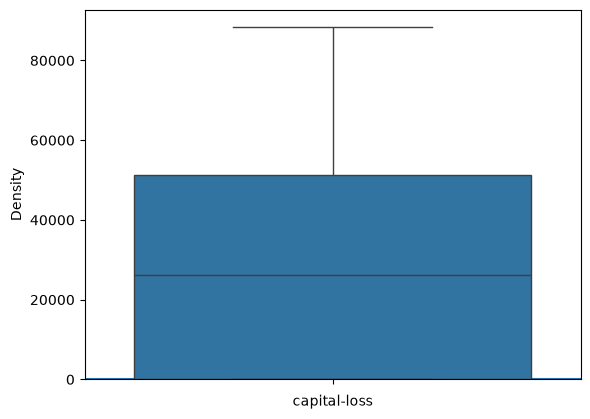

In [57]:
# Check data type and non-null count
df['capital-loss'].info()

# Summary statistics (including min, max, percentiles)
print(df['capital-loss'].describe())

#Cleaning special symbols like '$' and ','
df['capital-loss'] = (
    df['capital-loss']
    .astype(str)
    .str.replace(r'[\$,#,-]', '', regex=True)
    .str.strip()
)

#Replacing known missing string indicators with actual NaN
missing_placeholders = ['?', 'unknown', '-', '', 'nan', 'NaN', 'None']
df['capital-loss'] = df['capital-loss'].replace(missing_placeholders, np.nan)

df['capital-loss'] = pd.to_numeric(df['capital-loss'], errors='coerce')

# Impute using median
df['capital-loss'] = df['capital-loss'].fillna(df['capital-loss'].median())

# sns.kdeplot(df['capital-loss'])

# sns.boxplot(df['capital-loss'])

# Check top maximum values
print(df['capital-loss'].nlargest(10))

# Clip values below 0 to 0
df['capital-loss'] = df['capital-loss'].clip(lower=0)

# Cap extreme values at the 99th percentile
upper_limit = df['capital-loss'].quantile(0.99)
df['capital-loss'] = np.where(df['capital-loss'] > upper_limit, upper_limit, df['capital-loss'])

sns.kdeplot(df['capital-loss'])

sns.boxplot(df['capital-loss'])



### capital-gains

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: capital-gains
Non-Null Count  Dtype
--------------  -----
9354 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
count     9354
unique    1043
top          0
freq      4402
Name: capital-gains, dtype: object
Missing values: 356
91      9999999.0
1251    9999999.0
2688    9999999.0
2831    9999999.0
3635    9999999.0
5993    9999999.0
8016    9999999.0
8142    9999999.0
8248    9999999.0
9066    9999999.0
Name: capital-gains, dtype: float64


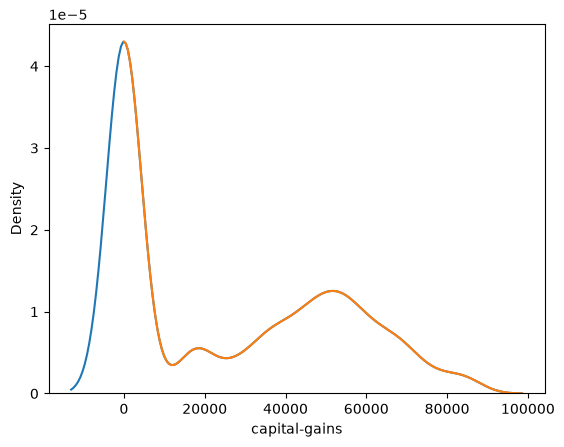

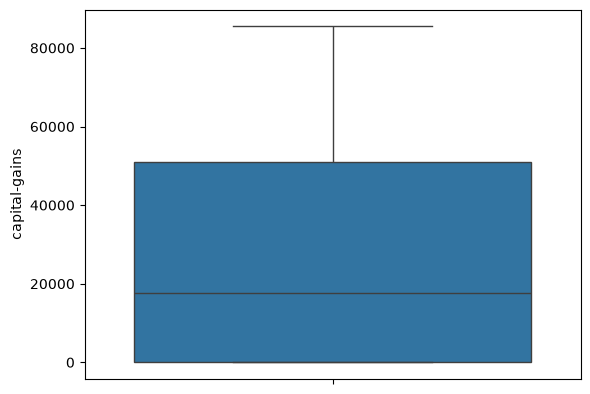

Remaining missing values: 0
Data type: float64


In [58]:
# Check data type and non-null count
df['capital-gains'].info()

# Summary statistics (including min, max, percentiles)
print(df['capital-gains'].describe())

# Check count of missing values
print("Missing values:", df['capital-gains'].isnull().sum())

# Cleaning special symbols like '$' and ','
df['capital-gains'] = (
    df['capital-gains']
    .astype(str)
    .str.replace(r'[\$,#,-]', '', regex=True)
    .str.strip()
)

# Replacing known missing string indicators with actual NaN
missing_placeholders = ['?', 'unknown', '-', '', 'nan', 'NaN', 'None']
df['capital-gains'] = df['capital-gains'].replace(missing_placeholders, np.nan)

df['capital-gains'] = pd.to_numeric(df['capital-gains'], errors='coerce')

# Check top maximum values
print(df['capital-gains'].nlargest(10))

# Clip values below 0 to 0
df['capital-gains'] = df['capital-gains'].clip(lower=0)

# Cap extreme values at the 99th percentile
upper_limit = df['capital-gains'].quantile(0.99)
df['capital-gains'] = np.where(df['capital-gains'] > upper_limit, upper_limit, df['capital-gains'])

# Impute missing values (NaN) with the median of the column so it leaves 0 nulls
df['capital-gains'] = df['capital-gains'].fillna(df['capital-gains'].median())

# Convert to float64 to ensure standard numeric dtype
df['capital-gains'] = df['capital-gains'].astype(float)

# Plotting distributions and boxplots
sns.kdeplot(df['capital-gains'])
sns.kdeplot(df['capital-gains'], clip=(0, None))
plt.show()

sns.boxplot(df['capital-gains'])
plt.show()

print("Remaining missing values:", df['capital-gains'].isnull().sum())
print("Data type:", df['capital-gains'].dtype)

### incident_date

In [59]:
df['incident_date'].info()

df['incident_date'].describe()

# Convert to datetime handling mixed formats automatically
df['incident_date'] = pd.to_datetime(
    df['incident_date'], format='mixed', dayfirst=True, errors='coerce'
)

# Check count of missing/invalid dates
missing_dates = df['incident_date'].isna().sum()
print(f"Total missing dates: {missing_dates}")

# Fill missing dates with the median date of the column
median_date = df['incident_date'].median()
df['incident_date'] = df['incident_date'].fillna(median_date)

# (Alternative) Or fill with a specific fixed default date string:
# df['incident_date'] = df['incident_date'].fillna(pd.to_datetime('2015-01-01'))

# Verify that there are zero missing dates left
print(f"Remaining missing dates after fill: {df['incident_date'].isna().sum()}")

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: incident_date
Non-Null Count  Dtype
--------------  -----
9680 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Total missing dates: 55
Remaining missing dates after fill: 0


In [60]:
# IQR Outlier Analysis

Q1 = df["incident_date"].quantile(0.25)
Q3 = df["incident_date"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Find outliers
outliers = df[
    (df["incident_date"] < lower_bound)
    | (df["incident_date"] > upper_bound)
]
print("Number of outliers:", len(outliers))

Number of outliers: 217


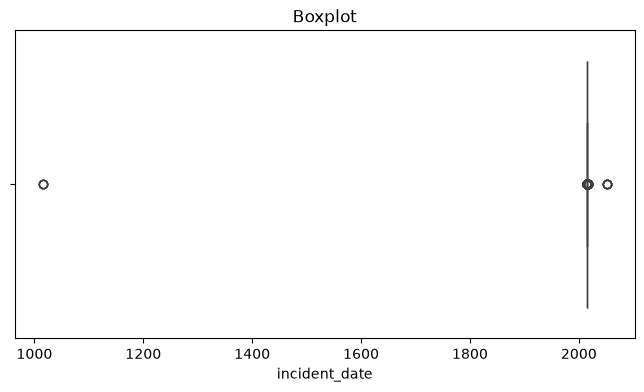

In [61]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["incident_date"])
plt.title("Boxplot")
plt.show()

In [62]:
# Outliers capping

df["incident_date"] = df["incident_date"].clip(
    lower=lower_bound, upper=upper_bound
)

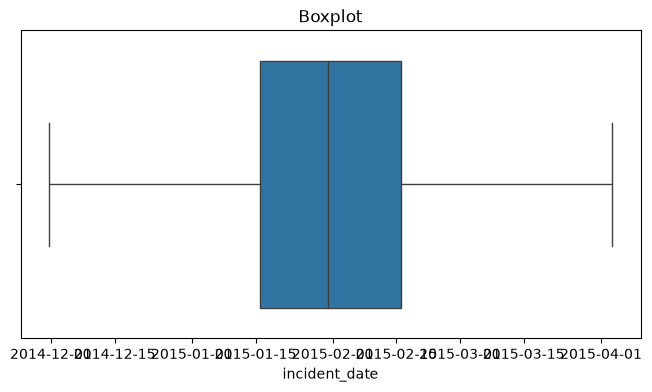

In [63]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["incident_date"])
plt.title("Boxplot")
plt.show()

In [64]:
"""
Machine learning models cannot directly take datetime objects. 
Once converted to datetime, extract useful numeric feature components:
"""
# Extract datetime features
df['incident_year'] = df['incident_date'].dt.year.astype("Int64")
df['incident_month'] = df['incident_date'].dt.month.astype("Int64")
df['incident_day'] = df['incident_date'].dt.day.astype("Int64")
df['incident_dayofweek'] = df['incident_date'].dt.dayofweek.astype("Int64")  # 0=Monday, 6=Sunday
df['incident_is_weekend'] = (
    df['incident_dayofweek'].isin([5, 6]).astype(int)
)  # Useful for claim risk analysis

# Drop the original datetime column to prevent type errors in model training & VIF calculations
df = df.drop(columns=['incident_date'])

### incident_type

In [65]:
df['incident_type'].info()

df['incident_type'].describe()

df['incident_type'].unique()



import difflib

# 1. Define the exact target categories
valid_categories = [
    'Single Vehicle Collision',
    'Multi-vehicle Collision',
    'Parked Car',
    'Vehicle Theft'
]

# 2. Step 1: Pre-clean whitespace and normalize formatting
# Convert to string, lowercase, strip spaces, and normalize underscores/extra spaces
df['incident_type_clean'] = (
    df['incident_type']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Replace common unknown/null placeholders with NaN upfront
invalid_placeholders = ['nan', 'None', 'null', '?', '-', 'Unknown', ' ', '']
df['incident_type_clean'] = df['incident_type_clean'].replace(invalid_placeholders, np.nan)

# 3. Step 2: Build auto_typo_map using difflib
auto_typo_map = {}

# Convert valid categories to lowercase for matching
valid_categories_lower = [cat.lower() for cat in valid_categories]

for val in df['incident_type_clean'].dropna().unique():
    val_lower = val.lower()
    
    # Check close matches using string similarity
    matches = difflib.get_close_matches(val_lower, valid_categories_lower, n=1, cutoff=0.4)
    
    if matches:
        # Find index of matched lower string to get the correctly capitalized category
        matched_idx = valid_categories_lower.index(matches[0])
        auto_typo_map[val] = valid_categories[matched_idx]

# 4. Step 3: Map mapped values back onto the clean column
df['incident_type'] = df['incident_type_clean'].map(auto_typo_map)

# Remove temporary clean working column
df.drop(columns=['incident_type_clean'], inplace=True)

# 5. Step 4: Verify the output
print("Unique categories remaining:", df['incident_type'].nunique())
print(df['incident_type'].value_counts(dropna=False))

# Replaced NaN values with 'Unknown'
df['incident_type'] = df['incident_type'].fillna('Unknown')

df['incident_type'].unique()

# Applied one-hot encoding
df = pd.get_dummies(df, columns=['incident_type'], drop_first=False, dtype=int)

# droping "incident_type_Unknown" column
df.drop(columns=['incident_type_Unknown'], inplace=True)

# Verified one-hot encoded Feature by filtering all dummy columns created for incident_type
encoded_cols_incident_type = [col for col in df.columns if col.startswith('incident_type')]
print(encoded_cols_incident_type)

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: incident_type
Non-Null Count  Dtype
--------------  -----
9665 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Unique categories remaining: 4
incident_type
Multi-vehicle Collision     3969
Single Vehicle Collision    3897
Vehicle Theft                923
Parked Car                   858
NaN                           63
Name: count, dtype: int64
['incident_type_Multi-vehicle Collision', 'incident_type_Parked Car', 'incident_type_Single Vehicle Collision', 'incident_type_Vehicle Theft']


### collision_type

In [66]:
df['collision_type'].info()

df['collision_type'].describe()

df['collision_type'].unique()

import difflib

# 1. Define the exact target categories
valid_categories = ["Front Collision", "Rear Collision", "Side Collision"]

# 2. Step 1: Pre-clean whitespace and normalize formatting
df['collision_type_clean'] = (
    df['collision_type']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Replace common unknown/null placeholders with NaN upfront
invalid_placeholders = ['nan', 'None', 'null', '?', '-', 'Unknown','unknown', ' ', '']
df['collision_type_clean'] = df['collision_type_clean'].replace(invalid_placeholders, np.nan)

# 3. Step 2: Build auto_typo_map using difflib
auto_typo_map = {}
valid_categories_lower = [cat.lower() for cat in valid_categories]

for val in df['collision_type_clean'].dropna().unique():
    val_lower = val.lower()
    matches = difflib.get_close_matches(val_lower, valid_categories_lower, n=1, cutoff=0.4)
    if matches:
        matched_idx = valid_categories_lower.index(matches[0])
        auto_typo_map[val] = valid_categories[matched_idx]

# 4. Step 3: Map cleaned values onto collision_type using replace to preserve unmatched valid entries
df['collision_type'] = df['collision_type_clean'].replace(auto_typo_map)

# Remove temporary clean working column
df.drop(columns=['collision_type_clean'], inplace=True)

# 5. Step 4: Verify output
print("Unique categories remaining:", df['collision_type'].nunique())
print(df['collision_type'].value_counts(dropna=False))

# Replaced NaN values with 'Unknown'
df['collision_type'] = df['collision_type'].fillna('Unknown')

df['collision_type'].unique()

# Applied one-hot encoding
df = pd.get_dummies(df, columns=['collision_type'], drop_first=False, dtype=int)

# droping "collision_type_Unknown" column
df.drop(columns=['collision_type_Unknown'], inplace=True)
# Verified one-hot encoded Feature by filtering all dummy columns created for collision_type
encoded_cols_collision_type = [col for col in df.columns if col.startswith('collision_type')]
print(encoded_cols_collision_type)


<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: collision_type
Non-Null Count  Dtype
--------------  -----
9533 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Unique categories remaining: 3
collision_type
Rear Collision     2737
Side Collision     2603
Front Collision    2371
NaN                1999
Name: count, dtype: int64
['collision_type_Front Collision', 'collision_type_Rear Collision', 'collision_type_Side Collision']


### incident_severity

In [67]:
df['incident_severity'].info()

df['incident_severity'].describe()

df['incident_severity'].unique()

import difflib

# 1. Define the exact target categories
valid_categories = ["Major Damage", "Minor Damage", "Trivial Damage", "Total Loss", ]

# 2. Step 1: Pre-clean whitespace and normalize formatting
df['incident_severity_clean'] = (
    df['incident_severity']
    .astype(str)
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Replace common unknown/null placeholders with NaN upfront
invalid_placeholders = ['nan', 'None', 'null', '?', '-', 'Unknown','unknown', ' ', '']
df['incident_severity_clean'] = df['incident_severity_clean'].replace(invalid_placeholders, np.nan)

# 3. Step 2: Build auto_typo_map using difflib
auto_typo_map = {}
valid_categories_lower = [cat.lower() for cat in valid_categories]

for val in df['incident_severity_clean'].dropna().unique():
    val_lower = val.lower()
    matches = difflib.get_close_matches(val_lower, valid_categories_lower, n=1, cutoff=0.4)
    if matches:
        matched_idx = valid_categories_lower.index(matches[0])
        auto_typo_map[val] = valid_categories[matched_idx]

# 4. Step 3: Map cleaned values onto collision_type using replace to preserve unmatched valid entries
df['incident_severity'] = df['incident_severity_clean'].replace(auto_typo_map)

# Remove temporary clean working column
df.drop(columns=['incident_severity_clean'], inplace=True)

# 5. Step 4: Verify output
print("Unique categories remaining:", df['incident_severity'].nunique())
print(df['incident_severity'].value_counts(dropna=False))

# Replaced NaN values with 'Unknown'
df['incident_severity'] = df['incident_severity'].fillna('Unknown')

df['incident_severity'].unique()

# Applied one-hot encoding
df = pd.get_dummies(df, columns=['incident_severity'], drop_first=False, dtype=int)

# droping "incident_severity_Unknown" column
df.drop(columns=['incident_severity_Unknown'], inplace=True)

# Verified one-hot encoded Feature by filtering all dummy columns created for incident_severity
encoded_cols_incident_severity = [col for col in df.columns if col.startswith('incident_severity')]
print(encoded_cols_incident_severity)

<class 'pandas.Series'>
Index: 9710 entries, 0 to 9999
Series name: incident_severity
Non-Null Count  Dtype
--------------  -----
9609 non-null   str  
dtypes: str(1)
memory usage: 151.7 KB
Unique categories remaining: 4
incident_severity
Minor Damage      3384
Major Damage      2654
Total Loss        2605
Trivial Damage     924
NaN                143
Name: count, dtype: int64
['incident_severity_Major Damage', 'incident_severity_Minor Damage', 'incident_severity_Total Loss', 'incident_severity_Trivial Damage']


## Mukesh

#### authorities_contacted

In [68]:
df['authorities_contacted'].nunique() # total unique count in feature 45
df['authorities_contacted'].value_counts()  # count with unique vale NAN is not count
df['authorities_contacted'].unique()  # 45 unique vale present with including wrong spelling 
df['authorities_contacted'] = df['authorities_contacted'].str.strip().str.upper()
df['authorities_contacted'] = df['authorities_contacted'].replace({"AMBULANCE SERVICE":"Ambulance",
                                                                  "AMBLUANCE":"Ambulance",
                                                                  "ABMULANCE":"Ambulance",
                                                                  "AMBULANCE":"Ambulance"})

df['authorities_contacted'] = df['authorities_contacted'].replace({"POLICE":"Police",
                                                                  "POLIE":"Police",
                                                                  "PLICE":"Police",
                                                                  "PLOICE":"Police",
                                                                  "POILCE":"Police",
                                                                  "POLICCE":"Police",
                                                                  "POLICE DEPT":"Police",
                                                                  "POLICE DEPT.":"Police"})

df['authorities_contacted'] = df['authorities_contacted'].replace({"FIRE":"Fire",             
                                                                    "IFRE":"Fire",                
                                                                    "FRIE":"Fire",            
                                                                    "FIIRE":"Fire",
                                                                    "FIRE DEPT" : "Fire",
                                                                    "FIRE BRIGADE":"Fire"})

df['authorities_contacted'] = df['authorities_contacted'].replace({"OTHER":"Other",
                                                                   "OTHERS":"Other",
                                                                   "OHTER":"Other",
                                                                   "TOHER":"Other",
                                                                   "OTEHR":"Other",})

# df['authorities_contacted'] = df['authorities_contacted'].replace({"?":"Unknown",           
#                                                                     "EMS":"Unknown",            
#                                                                     "-":"Unknown",          
#                                                                     " ":"Unknown",              
#                                                                     "UNKNOWN":"Unknown",
#                                                                     np.nan : "Unknown"})    

df['authorities_contacted'] = ( df['authorities_contacted'].astype('string').str.strip().replace({
                                                                                                    '?': 'Unknown',
                                                                                                    'EMS': 'Unknown',
                                                                                                    '-': 'Unknown',
                                                                                                    '': 'Unknown',
                                                                                                    'UNKNOWN': 'Unknown',
                                                                                                    'nan': 'Unknown'
                                                                                                    }).fillna('Unknown'))

# Apply one-hot encoding for authorities_contacted
df = pd.get_dummies(df, columns=["authorities_contacted"], drop_first=False, dtype=int)

# Droped the 'Unknown' column
if 'authorities_contacted_Unknown' in df.columns:
    df.drop(columns=['authorities_contacted_Unknown'], inplace=True)

#### incident_state

In [69]:
df['incident_state'] = df['incident_state'].str.strip().str.upper()

replace_vale = {
    "WV": "West Virginia",
    "WEST VIRGINIA": "West Virginia",
    "W.VA.": "West Virginia",
    "W. VIRGINIA": "West Virginia",
    "VA": "Virginia",
    "VIRGINIA": "Virginia",
    "SC": "South Carolina",
    "SOUTH CAROLINA": "South Carolina",
    "S.C.": "South Carolina",
    "NY": "New York",
    "NEW YORK": "New York",
    "N.Y.": "New York",
    "NC": "North Carolina",
    "NORTH CAROLINA": "North Carolina",
    "N.C.": "North Carolina",
    "PA": "Pennsylvania",
    "PENNSYLVANIA": "Pennsylvania",
    "PENN.": "Pennsylvania",
    "OH": "Ohio",
    "OHIO": "Ohio"
}

# 1. Map abbreviations/typos to proper names
df['incident_state'] = df['incident_state'].replace(replace_vale)

# 2. Replace invalid/missing placeholders with 'Unknown'
df['incident_state'] = df['incident_state'].replace({"?": "Unknown", "UNKNOWN": "Unknown", "-": "Unknown", "": "Unknown"})

# 3. Fill any lingering nulls with 'Unknown'
df['incident_state'] = df['incident_state'].fillna('Unknown')

# 4. Apply One-Hot Encoding (matching your project pipeline)
df = pd.get_dummies(df, columns=['incident_state'], drop_first=False, dtype=int)

# 5. Drop the 'incident_state_Unknown' column
if 'incident_state_Unknown' in df.columns:
    df.drop(columns=['incident_state_Unknown'], inplace=True)


#### incident_hour_of_the_day

In [70]:
def convert_into_hour(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    if x in ["", "--", "?"]:
        return np.nan

    if ":" in x:
        return int(x.split(":")[0])

    if "AM" in x or "PM" in x:
        return pd.to_datetime(x, format="%I %p").hour

    try:
        return int(float(x))
    except:
        return np.nan


df["incident_hour_of_the_day"] = df["incident_hour_of_the_day"].apply(convert_into_hour)

df['incident_hour_of_the_day'] = df['incident_hour_of_the_day'].replace([-1, 99,24,25], np.nan)
df['incident_hour_of_the_day'] = df['incident_hour_of_the_day'].fillna(df['incident_hour_of_the_day'].median())
df["incident_hour_of_the_day"].astype(int)

0       12
1       16
2       10
3       17
4        3
        ..
9995     7
9996     1
9997     0
9998    13
9999     3
Name: incident_hour_of_the_day, Length: 9710, dtype: int64

#### number_of_vehicles_involved

In [71]:
df['number_of_vehicles_involved'].unique()

word_to_num = {
        "One": 1,
        "Two": 2,
        "Three": 3,
        "Four": 4
}

df['number_of_vehicles_involved'] = (df['number_of_vehicles_involved'].replace(['--', '?', '-'], np.nan))
df['number_of_vehicles_involved'] = pd.to_numeric(df['number_of_vehicles_involved'],errors='coerce')
df['number_of_vehicles_involved'] = df['number_of_vehicles_involved'].replace(word_to_num)
df['number_of_vehicles_involved'] = ( df['number_of_vehicles_involved'].fillna(df['number_of_vehicles_involved'].median()))

# sns.boxplot(df['number_of_vehicles_involved'])

Q1 = df['number_of_vehicles_involved'].quantile(0.25)
Q3 = df['number_of_vehicles_involved'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df['number_of_vehicles_involved'] = df['number_of_vehicles_involved'].clip(lower=lower, upper=upper)

df['number_of_vehicles_involved'] = df['number_of_vehicles_involved'].astype(int)


#### property_damage

In [72]:
# Step 1: Clean and standardize property_damage column name and values
df['property_damage'] = df['property_damage'].astype(str).str.strip().str.upper()

df['property_damage'] = df['property_damage'].replace({
    "YES": "Yes",
    'Y': "Yes",
    '1': "Yes",
    "TRUE": "Yes",
    "NO": "No",
    "N": "No",
    "FALSE": "No",
    "0": "No",
    "?": "Unknown",
    "UNKNOWN": "Unknown",
    "-": "Unknown",
    "": "Unknown",
    "NAN": "Unknown",
    "NONE": "Unknown"
})

# Step 2: Fill any missing values with 'Unknown'
df['property_damage'] = df['property_damage'].fillna("Unknown")

# Step 3: Apply One-Hot Encoding
df = pd.get_dummies(df, columns=["property_damage"], drop_first=True, dtype=int)

#### 8 bodily_injuries

<Axes: ylabel='bodily_injuries'>

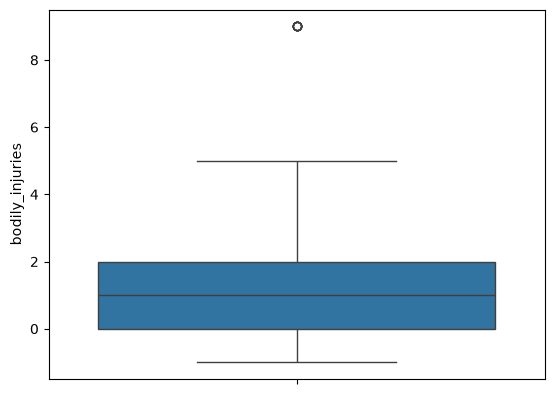

In [73]:
df['bodily_injuries'] = (df['bodily_injuries'].replace({'-': np.nan, '--': np.nan, '?': np.nan, -1: np.nan}).pipe(pd.to_numeric, errors='coerce'))
df['bodily_injuries'] = df['bodily_injuries'].fillna(df['bodily_injuries'].median())
df['bodily_injuries'] = df['bodily_injuries'].astype(int) #Convert back to integer
sns.boxplot(df['bodily_injuries'])

<Axes: xlabel='bodily_injuries', ylabel='Density'>

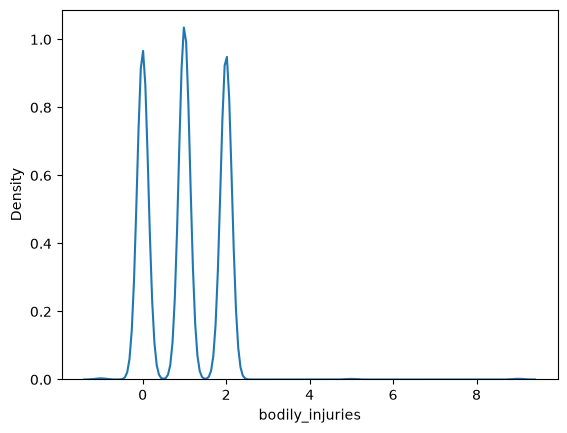

In [74]:
sns.kdeplot(df['bodily_injuries'])

<Axes: ylabel='bodily_injuries'>

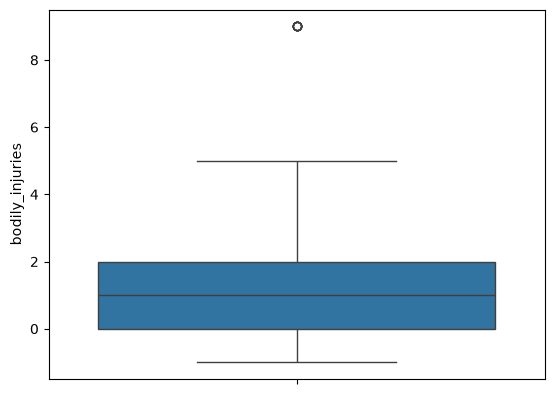

In [75]:
sns.boxplot(df['bodily_injuries'])

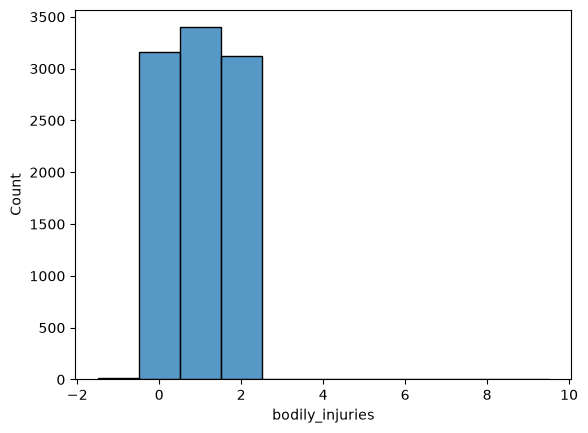

In [76]:
sns.histplot(data=df, x='bodily_injuries', discrete=True)
plt.show()

In [77]:

Q1 = df["bodily_injuries"].quantile(0.25)
Q3 = df["bodily_injuries"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

df["bodily_injuries"] = df["bodily_injuries"].clip(lower=lower_bound, upper=upper_bound)

Q1: 0.0
Q3: 2.0
IQR: 2.0
Lower bound: -3.0
Upper bound: 5.0


<Axes: ylabel='bodily_injuries'>

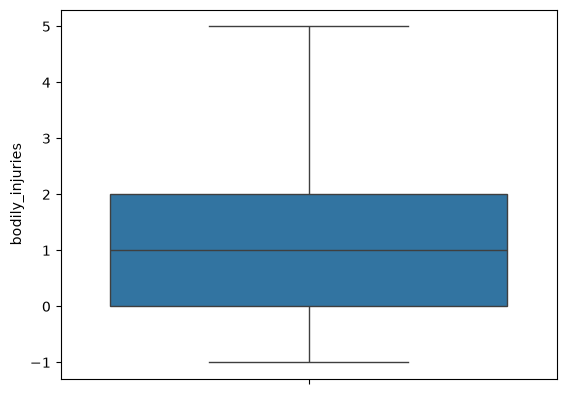

In [78]:
sns.boxplot(df['bodily_injuries'])

## Pooja

### witnesses

In [79]:
df['witnesses']

df['witnesses'].unique() 

df['witnesses'] = df['witnesses'].replace(['?', '-', '--'], np.nan)  #Convert invalid symbols to NaN

df['witnesses'].value_counts(dropna=False)

df['witnesses'] = pd.to_numeric(df['witnesses'], errors='coerce')  #Convert column to numeric

df.loc[df['witnesses'] < 0, 'witnesses'] = np.nan  #replace -1 into nan

df.loc[~df['witnesses'].isin([0, 1, 2, 3]), 'witnesses'] = np.nan # repalce 12 and 99 into nan

median_witnesses = df['witnesses'].median()

df['witnesses'] = df['witnesses'].fillna(median_witnesses)

df['witnesses'] = df['witnesses'].astype(int)

df['witnesses'].value_counts().sort_index()

witnesses
0    2324
1    2364
2    2707
3    2315
Name: count, dtype: int64

### police_report_available

In [80]:
# Check unique values and value counts
df['police_report_available'].unique()
df['police_report_available'].value_counts(dropna=False)

# Remove extra spaces and convert to uppercase
df['police_report_available'] = df['police_report_available'].str.strip()
df['police_report_available'] = df['police_report_available'].str.upper()

# Standardize YES variants
df['police_report_available'] = df['police_report_available'].replace(['Y', '1', 'TRUE'], 'YES')

# Standardize NO variants
df['police_report_available'] = df['police_report_available'].replace(['N', '0', 'FALSE'], 'NO')

# Convert invalid values, placeholders, and unknowns to NaN
df['police_report_available'] = df['police_report_available'].replace(['-', 'UNKNOWN', '', '?', 'NAN', 'NONE'], np.nan)

# DROP rows where police_report_available is NaN (Unknown / missing)
df = df.dropna(subset=['police_report_available'])

# Verify value counts of the cleaned column
print(df['police_report_available'].value_counts(dropna=False))

# Apply One-Hot Encoding
df = pd.get_dummies(df, columns=["police_report_available"], drop_first=True, dtype=int)

police_report_available
NO     3298
YES    2885
Name: count, dtype: int64


### total_claim_amount

In [81]:
df['total_claim_amount']

df['total_claim_amount'].unique() 

df['total_claim_amount'].value_counts(dropna=False)

#Remove $ and commas 
df['total_claim_amount'] = df['total_claim_amount'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)

#Convert to numeric
df['total_claim_amount'] = pd.to_numeric( df['total_claim_amount'], errors='coerce')

#Fill missing values
df['total_claim_amount'] = df['total_claim_amount'].fillna( df['total_claim_amount'].median())

df['total_claim_amount'] = df['total_claim_amount'].astype(int)

df['total_claim_amount'].value_counts().head()


total_claim_amount
57010    141
0         20
5900       8
4320       7
4950       7
Name: count, dtype: int64

### injury_claim

In [82]:
df['injury_claim'].head()

df['injury_claim'].unique() 

#Remove $ and commas 
df['injury_claim'] = ( df['injury_claim'].str.replace('$', '', regex=False).str.replace(',', '', regex=False))

# conver to numeric
df['injury_claim'] = pd.to_numeric(df['injury_claim'], errors='coerce')

#fill the missing value
df['injury_claim'] = df['injury_claim'].fillna( df['injury_claim'].median())

# convert in int
df['injury_claim'] = df['injury_claim'].astype(int)

df['injury_claim'].head()



0     6760
1     6020
3     6960
4     9270
5    18310
Name: injury_claim, dtype: int64

### property_claim

In [83]:
df['property_claim'].head()

df['property_claim'].unique() 

df['property_claim'] = ( df['property_claim'].str.replace('$', '', regex=False).str.replace(',', '', regex=False))

df['property_claim'] = pd.to_numeric(df['property_claim'], errors='coerce')

df['property_claim'] = df['property_claim'].fillna( df['property_claim'].median())

df['property_claim'] = df['property_claim'].astype(int)

df['property_claim'].head()

0     6200
1    12030
3    13910
4     4640
5    18310
Name: property_claim, dtype: int64

### vehicle_claim

In [84]:
df['vehicle_claim'].head()

df['vehicle_claim'].value_counts().head()

df['vehicle_claim'].unique() 

df['vehicle_claim'] = ( df['vehicle_claim'].str.replace('$', '', regex=False).str.replace(',', '', regex=False))

df['vehicle_claim'] = pd.to_numeric(df['vehicle_claim'], errors='coerce')

df['vehicle_claim'] = df['vehicle_claim'].fillna( df['vehicle_claim'].median())

df['vehicle_claim'] = df['vehicle_claim'].astype(int)

df['vehicle_claim'].head()



0    55810
1    48130
3    48680
4    32450
5    82400
Name: vehicle_claim, dtype: int64

### auto_make

In [85]:
# Step 1: Clean and standardize whitespace and case
df['auto_make'] = df['auto_make'].astype(str).str.strip().str.lower()

# Step 2: Convert invalid placeholders and 'unknown' strings to NaN
df['auto_make'] = df['auto_make'].replace(['?', '', '-', 'unknown', 'nan', 'none'], np.nan)

# Step 3: Standardize make names and typos
df['auto_make'] = df['auto_make'].replace({
    'suburu': 'subaru',
    'sbuuru': 'subaru',
    'subburu': 'subaru',
    'Sburu': 'subaru',
    'Subru': 'subaru',
    'sburu': 'subaru',
    'subru': 'subaru',
    
    'accura': 'acura',
    'accuura': 'acura',
    'accua': 'acura',

    'chevy': 'chevrolet',

    'volks wagen': 'volkswagen',
    'volkswagon': 'volkswagen',
    'vw': 'volkswagen',

    'mercedes benz': 'mercedes',
    'mercedes-benz': 'mercedes',
    'merceeds': 'mercedes',

    'jep': 'jeep',
    'ejep': 'jeep',

    'toytoa': 'toyota',
    'otyota': 'toyota',
    'Toyotta': 'toyota',
    'oTyota': 'toyota',
    'toyotta': 'toyota',

    'ddoge': 'dodge',
    'ddge': 'dodge',

    'sab': 'saab',
    'asab': 'saab',

    'honnda': 'honda',
    'hondda': 'honda',
    'hodna': 'honda',
    'Hnoda': 'honda',
    'hnoda': 'honda',

    'nisssan': 'nissan',
    'Nisssan': 'nissan',
    'Nissan ': 'nissan',

    'Chevvrolet': 'chevrrolet',
    'chevrrolet': 'chevrrolet',
    'chevrolet': 'chevrrolet',
    'chevvrolet': 'chevrrolet'
})

# Step 4: Drop rows where auto_make is NaN (Unknown / missing)
df = df.dropna(subset=['auto_make'])

# Step 5: Verify value counts of the cleaned column
print(df['auto_make'].value_counts())

# Step 6: Apply One-Hot Encoding
df = pd.get_dummies(df, columns=["auto_make"], drop_first=True, dtype=int)

auto_make
saab          507
subaru        507
dodge         474
chevrrolet    472
ford          442
nissan        441
acura         435
audi          431
volkswagen    431
bmw           425
jeep          402
mercedes      401
toyota        390
honda         347
chevrolet      17
Name: count, dtype: int64


### auto_year

In [86]:
df['auto_year'].head()

df['auto_year'].unique()
df['auto_year'] = df['auto_year'].replace(['-', '?', '--'], np.nan)
df['auto_year'] = pd.to_numeric( df['auto_year'], errors='coerce')
df.loc[ ~df['auto_year'].between(1995, 2015),'auto_year'] = np.nan
df['auto_year'] = df['auto_year'].fillna(df['auto_year'].median())
df['auto_year'] = df['auto_year'].astype("int32")
df['auto_year'].head()

0    1995
1    2014
3    2005
4    2005
5    2011
Name: auto_year, dtype: int32

In [87]:
df.info()

<class 'pandas.DataFrame'>
Index: 6122 entries, 0 to 9999
Data columns (total 90 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   months_as_customer                      6122 non-null   float64
 1   age                                     6122 non-null   float64
 2   policy_deductable                       6122 non-null   int64  
 3   policy_annual_premium                   6122 non-null   float64
 4   umbrella_limit                          6122 non-null   float64
 5   capital-gains                           6122 non-null   float64
 6   capital-loss                            6122 non-null   float64
 7   incident_hour_of_the_day                6122 non-null   float64
 8   number_of_vehicles_involved             6122 non-null   int64  
 9   bodily_injuries                         6122 non-null   int64  
 10  witnesses                               6122 non-null   int64  
 11  total_c

## Model Building:

In [88]:
# Separate features (X) and target variable (y)
X = df.drop(columns=['fraud_reported'])
y = df['fraud_reported']

## Train_Test split:

In [97]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training Shape: {X_train.shape}")
print(f"Testing Shape : {X_test.shape}\n")
print("Raw train-test split completed successfully!")

Training Shape: (4897, 89)
Testing Shape : (1225, 89)

Raw train-test split completed successfully!


## Feature Selection

--- CORRELATION & COLLINEARITY FEATURE SELECTION ---
Selected exactly 15 features out of 89

1. incident_severity_Major Damage
2. incident_severity_Minor Damage
3. incident_severity_Total Loss
4. vehicle_claim
5. property_claim
6. incident_type_Vehicle Theft
7. injury_claim
8. total_claim_amount
9. incident_type_Parked Car
10. incident_severity_Trivial Damage
11. collision_type_Rear Collision
12. authorities_contacted_Fire
13. incident_type_Single Vehicle Collision
14. authorities_contacted_Other
15. authorities_contacted_Police


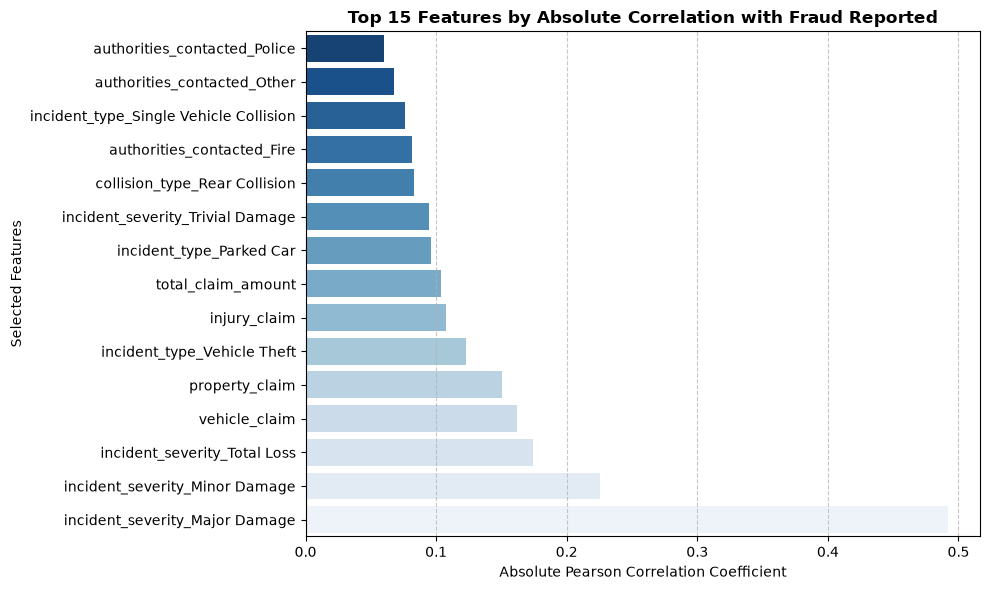

In [98]:
# STEP 1: Correlation & Collinearity Feature Selection (100% Deterministic)
# ==============================================================================
train_df = X_train.copy()
train_df['fraud_reported'] = y_train.values

# Calculate absolute Pearson correlation with the target variable
target_corr = train_df.corr()['fraud_reported'].abs()
target_corr = target_corr.drop('fraud_reported')

# Handle Multicollinearity: Drop features heavily correlated with each other (> 0.80)
corr_matrix = X_train.corr().abs()
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
to_drop = [
    column for column in upper_tri.columns if any(upper_tri[column] > 0.80)
]

# Remove collinear features
remaining_features = [col for col in X_train.columns if col not in to_drop]

# Select the top 15 features based on highest correlation with the target
selected_features_list = (
    target_corr[remaining_features].nlargest(15).index.tolist()
)

# Filter training and testing sets to raw selected subsets
X_train_selected = X_train[selected_features_list]
X_test_selected = X_test[selected_features_list]

print(f'--- CORRELATION & COLLINEARITY FEATURE SELECTION ---')
print(
    f'Selected exactly {len(selected_features_list)} features out of {X_train.shape[1]}\n'
)
for i, feature in enumerate(selected_features_list, 1):
    print(f'{i}. {feature}')

# STEP 2: Visualizing the Top 15 Selected Features
# ==============================================================================
plt.figure(figsize=(10, 6))
correlation_values = target_corr[selected_features_list].sort_values(
    ascending=True
)

ax = sns.barplot(
    x=correlation_values.values, y=correlation_values.index, palette='Blues_r'
)
plt.title(
    'Top 15 Features by Absolute Correlation with Fraud Reported',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Absolute Pearson Correlation Coefficient', fontsize=10)
plt.ylabel('Selected Features', fontsize=10)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Baseline pipeline:

In [99]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

print(f'Training Shape: {X_train_selected.shape}')
print(f'Testing Shape : {X_test_selected.shape}\n')

# Build Pipeline: Scaling and SMOTE occur strictly inside CV / training folds
baseline_pipeline = ImbPipeline(
    [
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy=0.6, random_state=42)),
        (
            'knn',
            KNeighborsClassifier(
                n_neighbors=11, weights='uniform', metric='minkowski', p=2
            ),
        ),
    ]
)

# Fit on raw selected training data
baseline_pipeline.fit(X_train_selected, y_train)

# Predictions
y_train_pred = baseline_pipeline.predict(X_train_selected)
y_test_pred = baseline_pipeline.predict(X_test_selected)
y_test_proba = baseline_pipeline.predict_proba(X_test_selected)[:, 1]

# Evaluation Prints
print('==================================================')
print('        BASELINE TRAINING SET RESULTS             ')
print('==================================================')
print(classification_report(y_train, y_train_pred))

print('==================================================')
print('         BASELINE TESTING SET RESULTS             ')
print('==================================================')
print(classification_report(y_test, y_test_pred))
print(f'\nBaseline Test Set ROC-AUC Score: {roc_auc_score(y_test, y_test_proba):.4f}')

Training Shape: (4897, 15)
Testing Shape : (1225, 15)

        BASELINE TRAINING SET RESULTS             
              precision    recall  f1-score   support

           0       0.89      0.85      0.87      3710
           1       0.59      0.67      0.63      1187

    accuracy                           0.81      4897
   macro avg       0.74      0.76      0.75      4897
weighted avg       0.82      0.81      0.81      4897

         BASELINE TESTING SET RESULTS             
              precision    recall  f1-score   support

           0       0.89      0.83      0.86       928
           1       0.56      0.67      0.61       297

    accuracy                           0.79      1225
   macro avg       0.72      0.75      0.73      1225
weighted avg       0.81      0.79      0.80      1225


Baseline Test Set ROC-AUC Score: 0.7778


## Hyperparameter tuning

In [100]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV

pipeline = ImbPipeline(
    [
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy=0.6, random_state=42)),
        ('knn', KNeighborsClassifier()),
    ]
)

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1,
)

# Fit using raw selected training data
grid_search.fit(X_train_selected, y_train)

print('--- BEST HYPERPARAMETERS ---')
print(grid_search.best_params_)

best_model = grid_search.best_estimator_

y_test_proba_tuned = best_model.predict_proba(X_test_selected)[:, 1]
print(
    f'\nTuned Test Set ROC-AUC Score: {roc_auc_score(y_test, y_test_proba_tuned):.4f}'
)

--- BEST HYPERPARAMETERS ---
{'knn__n_neighbors': 21, 'knn__p': 2, 'knn__weights': 'uniform'}

Tuned Test Set ROC-AUC Score: 0.7866


In [101]:
# 1. Predictions and probabilities on the training set
y_train_pred = best_model.predict(X_train_selected)
y_train_proba = best_model.predict_proba(X_train_selected)[:, 1]

# 2. Training evaluation metrics
print("--- TRAINING SET EVALUATION ---")
print(f"Training ROC-AUC Score: {roc_auc_score(y_train, y_train_proba):.4f}")
print("\nClassification Report (Training):")
print(classification_report(y_train, y_train_pred))
print("\nConfusion Matrix (Training):")
print(confusion_matrix(y_train, y_train_pred))

--- TRAINING SET EVALUATION ---
Training ROC-AUC Score: 0.8240

Classification Report (Training):
              precision    recall  f1-score   support

           0       0.89      0.86      0.87      3710
           1       0.60      0.66      0.63      1187

    accuracy                           0.81      4897
   macro avg       0.74      0.76      0.75      4897
weighted avg       0.82      0.81      0.81      4897


Confusion Matrix (Training):
[[3179  531]
 [ 405  782]]


In [102]:
# 1. Predictions and probabilities on the test set
y_test_pred = best_model.predict(X_test_selected)
y_test_proba = best_model.predict_proba(X_test_selected)[:, 1]

# 2. Tesing evaluation metrics
print("--- TEST SET EVALUATION ---")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_test_proba):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

--- TEST SET EVALUATION ---
ROC-AUC Score: 0.7866

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.85      0.87       928
           1       0.59      0.67      0.63       297

    accuracy                           0.81      1225
   macro avg       0.74      0.76      0.75      1225
weighted avg       0.82      0.81      0.81      1225


Confusion Matrix:
[[788 140]
 [ 97 200]]


## Model Explainability using SHAP

  0%|          | 0/100 [00:00<?, ?it/s]

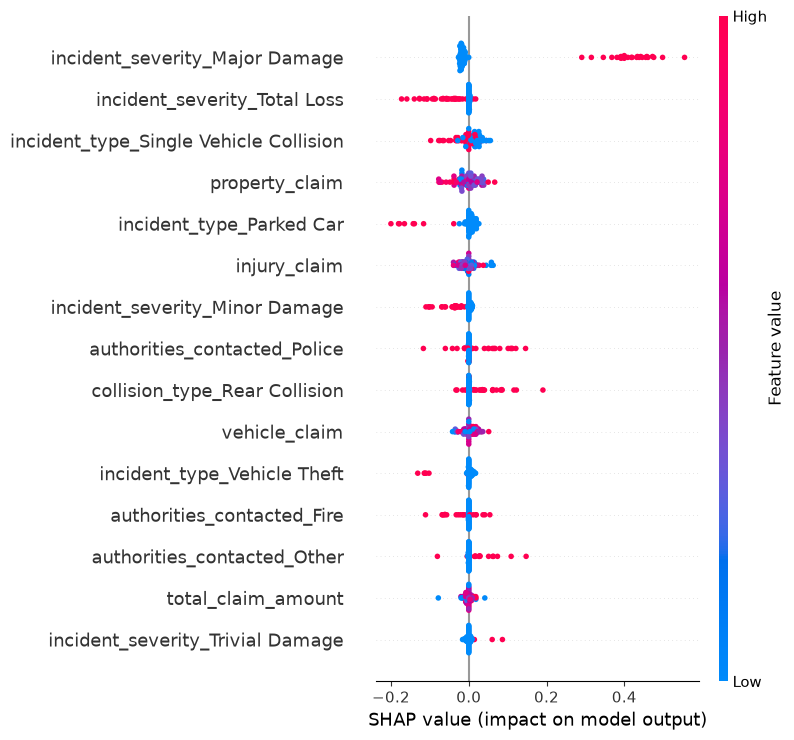

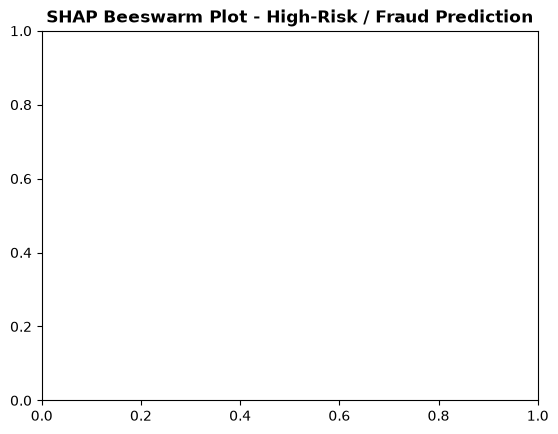

In [107]:
import matplotlib.pyplot as plt
import shap

# 1. Initialize background data using k-means summary for efficiency
background_data = shap.kmeans(X_train_selected, 50)


# 2. Define a clean wrapper function for probability predictions
def model_predict_proba(x):
  return best_model.predict_proba(x)


# 3. Instantiate KernelExplainer
explainer = shap.KernelExplainer(model=model_predict_proba, data=background_data)

# 4. Compute SHAP values on a subset of the test set (first 100 samples)
X_test_subset = X_test_selected.iloc[:100]
shap_values = explainer.shap_values(X_test_subset)

# 5. Extract values for Class 1 (Fraud Reported) safely
# If shap_values is a list, pick index [1]. If it's a 3D array or matrix, slice accordingly.
if isinstance(shap_values, list):
  shap_values_fraud = shap_values[1]
else:
  shap_values_fraud = (
      shap_values[:, :, 1] if len(shap_values.shape) == 3 else shap_values
  )

# ==============================================================================
# 6. Generate SHAP Visualizations
# ==============================================================================
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values_fraud, X_test_subset)
plt.title(
    'SHAP Beeswarm Plot - High-Risk / Fraud Prediction',
    fontsize=12,
    fontweight='bold',
)
plt.show()

In [109]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Extract feature importance ranking from your SHAP values
# Calculate the mean absolute SHAP value for each feature to find the most influential ones
mean_abs_shap = np.abs(shap_values_fraud).mean(axis=0)
shap_importance_df = pd.DataFrame({
    'feature': X_test_subset.columns,
    'shap_importance': mean_abs_shap
}).sort_values(by='shap_importance', ascending=False)

# 2. Select top features based on SHAP importance (e.g., top 10 most impactful features)
top_k = 10
shap_selected_features = shap_importance_df['feature'].head(top_k).tolist()

print(f"--- SHAP-BASED FEATURE SELECTION ---")
print(f"Selected top {top_k} features based on SHAP analysis:\n")
for i, feat in enumerate(shap_selected_features, 1):
    print(f"{i}. {feat}")

# 3. Filter your training and testing sets using the SHAP-selected features
X_train_shap = X_train_selected[shap_selected_features]
X_test_shap = X_test_selected[shap_selected_features]

# 4. Instantiate and train the KNN model on the SHAP-filtered feature subset
shap_knn_pipeline = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(sampling_strategy=0.6, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=21, weights='uniform', metric='minkowski', p=2))
])

print("\nTraining the final KNN model on SHAP-selected features...")
shap_knn_pipeline.fit(X_train_shap, y_train)

# 5. Make predictions and compute probabilities
y_train_pred_s = shap_knn_pipeline.predict(X_train_shap)
y_train_proba_s = shap_knn_pipeline.predict_proba(X_train_shap)[:, 1]

y_test_pred_s = shap_knn_pipeline.predict(X_test_shap)
y_test_proba_s = shap_knn_pipeline.predict_proba(X_test_shap)[:, 1]

# 6. Evaluation Metrics
print('=' * 50)
print('       SHAP-FILTERED KNN TRAINING RESULTS        ')
print('=' * 50)
print(f"Training ROC-AUC Score: {roc_auc_score(y_train, y_train_proba_s):.4f}\n")
print(classification_report(y_train, y_train_pred_s))

print('=' * 50)
print('       SHAP-FILTERED KNN TESTING RESULTS         ')
print('=' * 50)
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_test_proba_s):.4f}\n")
print(classification_report(y_test, y_test_pred_s))
print("Confusion Matrix (Test):")
print(confusion_matrix(y_test, y_test_pred_s))

--- SHAP-BASED FEATURE SELECTION ---
Selected top 10 features based on SHAP analysis:

1. incident_severity_Major Damage
2. incident_severity_Total Loss
3. incident_type_Single Vehicle Collision
4. property_claim
5. incident_type_Parked Car
6. injury_claim
7. incident_severity_Minor Damage
8. authorities_contacted_Police
9. collision_type_Rear Collision
10. vehicle_claim

Training the final KNN model on SHAP-selected features...
       SHAP-FILTERED KNN TRAINING RESULTS        
Training ROC-AUC Score: 0.8241

              precision    recall  f1-score   support

           0       0.88      0.86      0.87      3710
           1       0.60      0.65      0.62      1187

    accuracy                           0.81      4897
   macro avg       0.74      0.76      0.75      4897
weighted avg       0.82      0.81      0.81      4897

       SHAP-FILTERED KNN TESTING RESULTS         
Test Set ROC-AUC Score: 0.7944

              precision    recall  f1-score   support

           0       0.